# Ejercicios Prácticos - Predicción en Minería de Datos
**Materia:** Minería de Datos II - TC de IA
**Docente:** Ing. Esp. Daniela Coman
**Unidad 2:** Conceptos de Predicción

---
## Conceptos Fundamentales (Clase 04)

### ¿Qué es la Predicción?
La predicción utiliza datos históricos y actuales para pronosticar comportamientos y tendencias futuras. Detecta patrones en casos previos y los aplica a situaciones nuevas.

### Tipos de Aprendizaje Automático:
- **Supervisado:** Requiere datos etiquetados (entrada y salida). Objetivo: predecir o clasificar.
- **No supervisado:** Datos sin etiquetar. Objetivo: descubrir estructura oculta.
- **Semi-supervisado:** Pocos datos etiquetados + muchos sin etiquetar.

### Variables:
- **Dependiente (Objetivo/Label):** Variable que se desea predecir.
- **Independiente (Predictora/Feature):** Factores utilizados para predecir.

### División de Datos (Regla de Oro):
- **Entrenamiento:** Para que el modelo aprenda patrones.
- **Validación:** Para ajustar hiperparámetros y detectar sobreajuste.
- **Prueba:** Evaluación final en datos no vistos.

### Tipos de Problemas:
- **Regresión:** Predecir un valor continuo (precio, temperatura, ventas).
- **Clasificación:** Predecir una categoría discreta (spam/no spam, aprobado/rechazado).

---
## Instalación de Librerías Necesarias

In [8]:
# Instalamos las librerías necesarias para los ejercicios
# pandas: manipulación de datos en tablas
# numpy: cálculos numéricos y generación de datos aleatorios
# scikit-learn: algoritmos de machine learning y métricas de evaluación
# matplotlib: gráficos y visualizaciones
# seaborn: estadísticas visuales avanzadas
!pip install pandas numpy scikit-learn matplotlib seaborn

**Explicación:** Se instalan las librerías esenciales para minería de datos:
- **pandas** para crear y manipular DataFrames
- **numpy** para generar datos numéricos aleatorios
- **scikit-learn** para algoritmos de ML (Random Forest, Regresión Logística, etc.)
- **matplotlib/seaborn** para visualizar resultados

In [9]:
# Importamos todas las librerías que usaremos en los ejercicios
import pandas as pd              # Manipulación de datos en tablas (DataFrames)
import numpy as np               # Operaciones numéricas y generación de datos
import matplotlib.pyplot as plt  # Creación de gráficos
import seaborn as sns            # Gráficos estadísticos mejorados

# Módulos de scikit-learn para machine learning
from sklearn.model_selection import train_test_split  # Dividir datos en entrenamiento/prueba
from sklearn.ensemble import RandomForestClassifier    # Clasificador Random Forest
from sklearn.ensemble import RandomForestRegressor    # Regresor Random Forest
from sklearn.linear_model import LogisticRegression   # Regresión Logística (clasificación)
from sklearn.linear_model import LinearRegression     # Regresión Lineal (regresión)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix  # Métricas
from sklearn.metrics import mean_squared_error, r2_score  # Métricas para regresión

# Configuración para que los gráficos se muestren en la notebook
%matplotlib inline
print("Librerías importadas correctamente")

Librerías importadas correctamente


**Explicación:** Se importan todas las librerías necesarias:
- **pandas** crea tablas (DataFrames) para organizar los datos
- **numpy** genera datos numéricos aleatorios para simular datasets
- **train_test_split** divide los datos en conjuntos de entrenamiento (70%) y prueba (30%)
- **RandomForestClassifier/Regressor** son algoritmos de aprendizaje supervisado
- **accuracy_score** mide el porcentaje de aciertos del modelo
- **confusion_matrix** muestra errores y aciertos por clase

---
## EJERCICIO 1: Predicción de la Aprobación de un Préstamo

**Descripción:** Un banco quiere predecir si un solicitante será "aprobado" o "rechazado".

**Análisis:**
- **Variable Objetivo:** aprobado (sí/no) → Categórica binaria
- **Tipo de Problema:** Clasificación Binaria
- **Tipo de Aprendizaje:** Supervisado
- **Técnicas:** Regresión Logística, Random Forest, SVM, XGBoost

In [10]:
# EJERCICIO 1: Crear dataset de ejemplo para aprobación de préstamos
# ==================================================================

# Fijamos la semilla para que los datos aleatorios sean reproducibles
np.random.seed(42)

# Generamos 1000 solicitantes de préstamos con características aleatorias
n_solicitantes = 1000

# Creamos las variables predictoras (features)
historial_credito = np.random.randint(300, 850, n_solicitantes)  # Puntaje crediticio 300-850
ingresos = np.random.randint(1500, 15000, n_solicitantes)         # Ingresos mensuales en USD
edad = np.random.randint(18, 70, n_solicitantes)                 # Edad entre 18 y 70 años
monto_prestamo = np.random.randint(1000, 50000, n_solicitantes)  # Monto solicitado

# Definimos la variable objetivo (label): aprobado (1) o rechazado (0)
# Regla simple: se aprueba si historial > 600, ingresos > 3000 y monto < ingresos*3
aprobado = (
    (historial_credito > 600) &
    (ingresos > 3000) &
(monto_prestamo < ingresos * 3)
).astype(int)

# Creamos un DataFrame de pandas con todos los datos
df_prestamos = pd.DataFrame({
    'historial_credito': historial_credito,
    'ingresos': ingresos,
    'edad': edad,
    'monto_prestamo': monto_prestamo,
    'aprobado': aprobado
})

# Mostramos las primeras 5 filas para ver cómo se ven los datos
print("Dataset de Préstamos - Primeras 5 filas:")
print(df_prestamos.head())
print(f"\nTotal de registros: {len(df_prestamos)}")
print(f"Aprobados: {aprobado.sum()} | Rechazados: {n_solicitantes - aprobado.sum()}")

Dataset de Préstamos - Primeras 5 filas:
   historial_credito  ingresos  edad  monto_prestamo  aprobado
0                402      9492    30           19058         0
1                735      2145    39           12101         0
2                570     14518    38           41718         0
3                406      5763    39           33602         0
4                371     10301    45           10122         0

Total de registros: 1000
Aprobados: 207 | Rechazados: 793


**Explicación:**
- Se generan **1000 registros** simulados de solicitantes de préstamos
- Las **variables predictoras** son: historial crediticio (300-850), ingresos (1500-15000), edad (18-70) y monto solicitado
- La **variable objetivo** (`aprobado`) se genera con una regla lógica: se aprueba si el historial > 600, los ingresos > 3000 y el monto es menor a 3 veces los ingresos
- Se crea un **DataFrame de pandas** que organiza los datos en formato tabular
- Se imprime un resumen para verificar que los datos se generaron correctamente

In [11]:
# EJERCICIO 1: Entrenar modelo de clasificación
# ==================================================================

# Separamos las variables predictoras (X) de la variable objetivo (y)
X = df_prestamos[['historial_credito', 'ingresos', 'edad', 'monto_prestamo']]  # Features
y = df_prestamos['aprobado']  # Label (variable a predecir)

# Dividimos los datos: 70% entrenamiento, 30% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Creamos el modelo de Random Forest con 100 árboles de decisión
modelo_prestamo = RandomForestClassifier(n_estimators=100, random_state=42)

# Entrenamos el modelo con los datos de entrenamiento
modelo_prestamo.fit(X_train, y_train)

# Hacemos predicciones con los datos de prueba
y_pred = modelo_prestamo.predict(X_test)

# Evaluamos la precisión del modelo
precision = accuracy_score(y_test, y_pred)

print("EJERCICIO 1: Resultados - Aprobación de Préstamos")
print("=" * 55)
print(f"Precisión del modelo: {precision * 100:.2f}%")
print(f"\nDatos de entrenamiento: {len(X_train)} registros")
print(f"Datos de prueba: {len(X_test)} registros")

EJERCICIO 1: Resultados - Aprobación de Préstamos
Precisión del modelo: 99.67%

Datos de entrenamiento: 700 registros
Datos de prueba: 300 registros


**Explicación:**
- Se **separan** las variables predictoras (X) de la variable objetivo (y)
- Se **dividen** los datos: 70% para entrenar el modelo, 30% para probarlo (regla de oro)
- Se crea un **Random Forest** con 100 árboles de decisión (cada árbol aprende patrones diferentes)
- El método `.fit()` **entrena** el modelo: aprende la relación entre features y el resultado
- El método `.predict()` genera **predicciones** para los datos no vistos
- **accuracy_score** calcula el porcentaje de predicciones correctas

Reporte de Clasificación:
              precision    recall  f1-score   support

   Rechazado       1.00      1.00      1.00       236
    Aprobado       0.98      1.00      0.99        64

    accuracy                           1.00       300
   macro avg       0.99      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



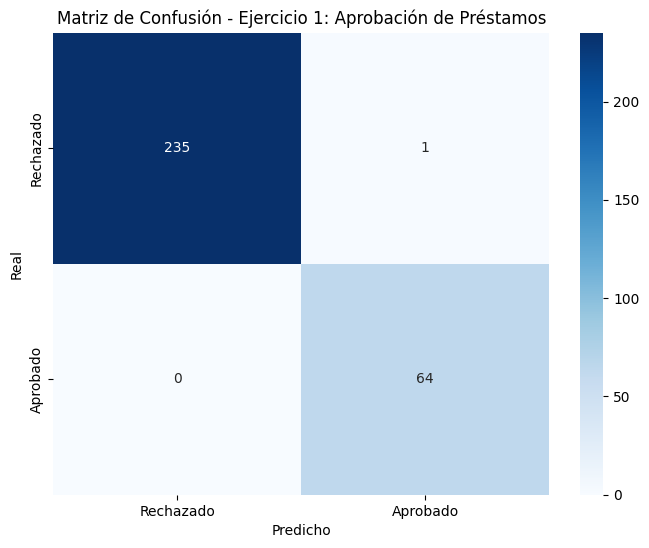

In [12]:
# EJERCICIO 1: Evaluar el modelo con métricas detalladas
# ==================================================================

# Mostramos el reporte de clasificación con precisión, recall y F1-score
print("Reporte de Clasificación:")
print("=" * 55)
print(classification_report(y_test, y_pred, target_names=['Rechazado', 'Aprobado']))

# Creamos la matriz de confusión para ver errores y aciertos
cm = confusion_matrix(y_test, y_pred)

# Visualizamos la matriz de confusión con seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rechazado', 'Aprobado'],
            yticklabels=['Rechazado', 'Aprobado'])
plt.title('Matriz de Confusión - Ejercicio 1: Aprobación de Préstamos')
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.show()

**Explicación:**
- **classification_report** muestra: precisión (% de predicciones correctas por clase), recall (% de casos reales detectados) y F1-score (promedio armónico)
- La **matriz de confusión** muestra: Verdaderos Negativos (arriba izq), Falsos Positivos (arriba der), Falsos Negativos (abajo izq), Verdaderos Positivos (abajo der)
- Un buen modelo debe tener valores altos en la diagonal principal (predicciones correctas)
- Los valores fuera de la diagonal representan **errores** del modelo

---
## EJERCICIO 2: Predicción del Precio de una Casa

**Descripción:** Una empresa de bienes raíces desea predecir el precio de venta de una casa.

**Análisis:**
- **Variable Objetivo:** precio (valor numérico continuo)
- **Tipo de Problema:** Regresión Continua
- **Tipo de Aprendizaje:** Supervisado
- **Técnicas:** Regresión Lineal, Random Forest, SVR, Gradient Boosting

In [13]:
# EJERCICIO 2: Crear dataset de ejemplo para precios de casas
# ==================================================================

np.random.seed(42)

# Generamos 500 casas con características aleatorias
n_casas = 500

# Variables predictoras (features)
habitaciones = np.random.randint(1, 6, n_casas)          # 1 a 5 habitaciones
metros_cuadrados = np.random.randint(40, 300, n_casas)   # 40 a 300 m²
antiguedad = np.random.randint(0, 50, n_casas)           # 0 a 50 años
ubicacion = np.random.choice(['Centro', 'Norte', 'Sur', 'Este'], n_casas)  # Zona

# Codificamos la ubicación a números (0, 1, 2, 3) para que el modelo lo entienda
# Cast to int32 to avoid OverflowError during multiplication with large numbers
ubicacion_num = pd.Categorical(ubicacion).codes.astype(np.int32)

# Variable objetivo: precio de la casa (regla con algo de variación aleatoria)
precio = (
    metros_cuadrados * 1500 +      # Precio base por m²
    habitaciones * 15000 +          # Plus por habitación
    antiguedad * (-2000) +          # Descuento por antigüedad
    ubicacion_num * 25000 +         # Plus por ubicación
    np.random.randint(-20000, 20000, n_casas)  # Variación aleatoria
)

# Creamos el DataFrame
df_casas = pd.DataFrame({
    'habitaciones': habitaciones,
    'metros_cuadrados': metros_cuadrados,
    'antiguedad': antiguedad,
    'ubicacion': ubicacion,
    'ubicacion_num': ubicacion_num,
    'precio': precio
})

print("Dataset de Casas - Primeras 5 filas:")
print(df_casas.head())
print(f"\nRango de precios: ${precio.min():,.0f} - ${precio.max():,.0f}")

Dataset de Casas - Primeras 5 filas:
   habitaciones  metros_cuadrados  antiguedad ubicacion  ubicacion_num  precio
0             4               101          46       Sur              3  190004
1             5               123          36    Centro              0  191589
2             3               256           2       Sur              3  516487
3             5               226          32    Centro              0  330302
4             5                58          27     Norte              2  169463

Rango de precios: $535 - $535,678


**Explicación:**
- Se generan **500 casas** con características variadas
- Las **features** incluyen: habitaciones (1-5), m² (40-300), antigüedad (0-50 años) y ubicación (4 zonas)
- La **variable objetivo** (`precio`) se calcula con una fórmula que combina todas las características más variación aleatoria
- La ubicación se **codifica** a números (0-3) porque los modelos solo entienden valores numéricos
- El precio varía según: m² (factor principal), habitaciones, antigüedad y ubicación

In [14]:
# EJERCICIO 2: Entrenar modelo de regresión
# ==================================================================

# Separamos variables predictoras y objetivo
X = df_casas[['habitaciones', 'metros_cuadrados', 'antiguedad', 'ubicacion_num']]
y = df_casas['precio']

# Dividimos en entrenamiento (70%) y prueba (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Creamos el modelo de Random Forest Regressor con 100 árboles
modelo_casa = RandomForestRegressor(n_estimators=100, random_state=42)

# Entrenamos el modelo
modelo_casa.fit(X_train, y_train)

# Hacemos predicciones
y_pred = modelo_casa.predict(X_test)

# Evaluamos con métricas de regresión
mse = mean_squared_error(y_test, y_pred)       # Error cuadrático medio
rmse = np.sqrt(mse)                             # Raíz del error cuadrático medio
r2 = r2_score(y_test, y_pred)                   # Coeficiente de determinación (0-1)

print("EJERCICIO 2: Resultados - Precio de Casas")
print("=" * 55)
print(f"Error Cuadrático Medio (MSE): ${mse:,.0f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): ${rmse:,.0f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")
print(f"\nInterpretación: El modelo explica el {r2*100:.1f}% de la variación del precio")

EJERCICIO 2: Resultados - Precio de Casas
Error Cuadrático Medio (MSE): $490,780,413
Raíz del Error Cuadrático Medio (RMSE): $22,154
Coeficiente de Determinación (R²): 0.9626

Interpretación: El modelo explica el 96.3% de la variación del precio


**Explicación:**
- Se crea un **Random Forest Regressor** (100 árboles) para predecir valores continuos
- **MSE** (Error Cuadrático Medio): promedio de los errores al cuadrado (menor es mejor)
- **RMSE** (Raíz del MSE): error promedio en las mismas unidades que la variable objetivo (precio)
- **R²** (Coeficiente de Determinación): mide qué tan bien el modelo explica la variación del precio (1.0 = perfecto, 0.0 = no explica nada)
- Un R² > 0.8 indica un buen modelo predictivo

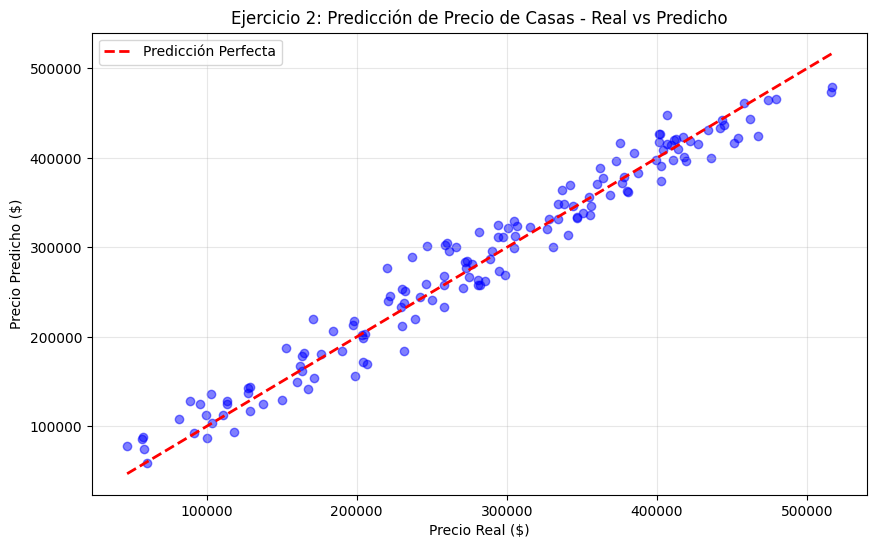

In [15]:
# EJERCICIO 2: Visualizar predicciones vs valores reales
# ==================================================================

plt.figure(figsize=(10, 6))

# Gráfico de dispersión: valores reales vs predicciones
plt.scatter(y_test, y_pred, alpha=0.5, color='blue')

# Línea de referencia perfecta (donde estarían las predicciones ideales)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', lw=2, label='Predicción Perfecta')

plt.xlabel('Precio Real ($)')
plt.ylabel('Precio Predicho ($)')
plt.title('Ejercicio 2: Predicción de Precio de Casas - Real vs Predicho')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Explicación:**
- El gráfico muestra los **precios reales** (eje X) vs los **precios predichos** (eje Y)
- La **línea roja punteada** representa la predicción perfecta (donde estarían los puntos si el modelo fuera perfecto)
- Cuanto más cerca estén los puntos de la línea roja, mejor es el modelo
- Los puntos dispersos indican **errores** del modelo en predicciones individuales

---
## EJERCICIO 3: Diagnóstico de Enfermedad (Diabetes)

**Descripción:** Un hospital desea predecir si un paciente tiene diabetes.

**Análisis:**
- **Variable Objetivo:** diabetes (sí/no) → Categórica binaria
- **Tipo de Problema:** Clasificación Binaria
- **Tipo de Aprendizaje:** Supervisado
- **Técnicas:** Regresión Logística, Random Forest, SVM, XGBoost

In [16]:
# EJERCICIO 3: Crear dataset de ejemplo para diagnóstico de diabetes
# ==================================================================

np.random.seed(42)

# Generamos 800 pacientes con datos de salud
n_pacientes = 800

# Variables predictoras (features clínicas)
edad = np.random.randint(20, 80, n_pacientes)                    # Edad 20-80 años
imc = np.random.uniform(18, 45, n_pacientes)                     # Índice de Masa Corporal
presion_arterial = np.random.randint(80, 180, n_pacientes)       # Presión sistólica
nivel_glucosa = np.random.randint(70, 250, n_pacientes)          # Glucosa en sangre
antecedentes_familiares = np.random.choice([0, 1], n_pacientes)  # 0=No, 1=Sí

# Variable objetivo: diabetes (1=Sí, 0=No)
# Regla: mayor riesgo con glucosa alta, IMC alto, antecedentes familiares
diabetes = (
    (nivel_glucosa > 140) |
    ((imc > 30) & (antecedentes_familiares == 1)) |
    ((edad > 50) & (nivel_glucosa > 120))
).astype(int)

# Creamos el DataFrame
df_diabetes = pd.DataFrame({
    'edad': edad,
    'imc': np.round(imc, 1),
    'presion_arterial': presion_arterial,
    'nivel_glucosa': nivel_glucosa,
    'antecedentes_familiares': antecedentes_familiares,
    'diabetes': diabetes
})

print("Dataset de Diabetes - Primeras 5 filas:")
print(df_diabetes.head())
print(f"\nPacientes con diabetes: {diabetes.sum()} | Sin diabetes: {n_pacientes - diabetes.sum()}")

Dataset de Diabetes - Primeras 5 filas:
   edad   imc  presion_arterial  nivel_glucosa  antecedentes_familiares  \
0    58  28.7               159            202                        0   
1    71  42.1               106            199                        0   
2    48  22.0               151            131                        0   
3    34  31.9               139            218                        0   
4    62  24.3               125            148                        1   

   diabetes  
0         1  
1         1  
2         0  
3         1  
4         1  

Pacientes con diabetes: 611 | Sin diabetes: 189


**Explicación:**
- Se generan **800 pacientes** con datos de salud realistas
- Las **features** son clínicas: edad, IMC, presión arterial, glucosa y antecedentes familiares
- La **variable objetivo** (`diabetes`) se define con reglas médicas: glucosa > 140, o IMC > 30 con antecedentes, o edad > 50 con glucosa > 120
- Esta fórmula simula factores de riesgo reales de diabetes tipo 2

In [17]:
# EJERCICIO 3: Entrenar modelo de clasificación
# ==================================================================

# Separamos variables predictoras y objetivo
X = df_diabetes[['edad', 'imc', 'presion_arterial', 'nivel_glucosa', 'antecedentes_familiares']]
y = df_diabetes['diabetes']

# Dividimos en entrenamiento (70%) y prueba (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Creamos el modelo de Random Forest
modelo_diabetes = RandomForestClassifier(n_estimators=100, random_state=42)

# Entrenamos el modelo
modelo_diabetes.fit(X_train, y_train)

# Hacemos predicciones
y_pred = modelo_diabetes.predict(X_test)

# Evaluamos la precisión
precision = accuracy_score(y_test, y_pred)

print("EJERCICIO 3: Resultados - Diagnóstico de Diabetes")
print("=" * 55)
print(f"Precisión del modelo: {precision * 100:.2f}%")
print(f"\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Sin Diabetes', 'Con Diabetes']))

EJERCICIO 3: Resultados - Diagnóstico de Diabetes
Precisión del modelo: 100.00%

Reporte de Clasificación:
              precision    recall  f1-score   support

Sin Diabetes       1.00      1.00      1.00        51
Con Diabetes       1.00      1.00      1.00       189

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



**Explicación:**
- Se entrenan **5 features clínicas** para predecir si un paciente tiene diabetes
- El **Random Forest** combina 100 árboles de decisión para mejorar la precisión
- En problemas médicos, es importante equilibrar **precisión** (no diagnosticar sano como enfermo) y **recall** (detectar todos los enfermos)
- Un modelo con alta precisión y alto recall es ideal para diagnósticos médicos

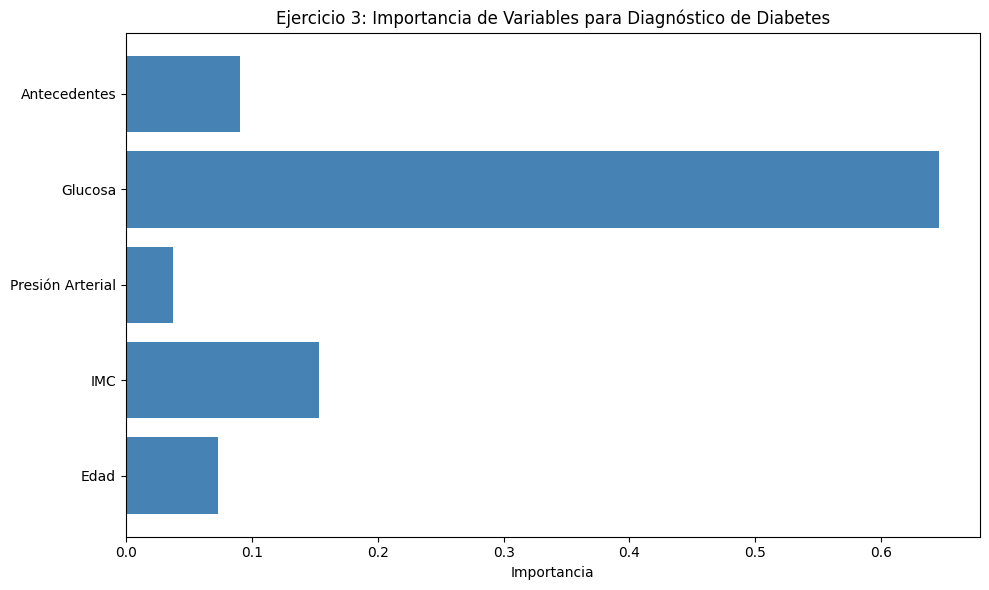


Importancia de cada variable:
  Edad: 0.0729 (7.3%)
  IMC: 0.1535 (15.3%)
  Presión Arterial: 0.0373 (3.7%)
  Glucosa: 0.6461 (64.6%)
  Antecedentes: 0.0903 (9.0%)


In [18]:
# EJERCICIO 3: Visualizar importancia de variables
# ==================================================================

# Obtenemos la importancia de cada variable en el modelo
importancias = modelo_diabetes.feature_importances_
nombres_variables = ['Edad', 'IMC', 'Presión Arterial', 'Glucosa', 'Antecedentes']

# Creamos un gráfico de barras con la importancia
plt.figure(figsize=(10, 6))
plt.barh(nombres_variables, importancias, color='steelblue')
plt.xlabel('Importancia')
plt.title('Ejercicio 3: Importancia de Variables para Diagnóstico de Diabetes')
plt.tight_layout()
plt.show()

print("\nImportancia de cada variable:")
for nombre, importancia in zip(nombres_variables, importancias):
    print(f"  {nombre}: {importancia:.4f} ({importancia*100:.1f}%)")

**Explicación:**
- **feature_importances_** indica qué variable contribuye más a las decisiones del modelo
- La **glucosa** y el **IMC** suelen ser las variables más importantes para diagnosticar diabetes
- El gráfico de barras muestra visualmente qué factores son más determinantes
- Esto ayuda a los médicos a entender qué parámetros monitorear más closely

---
## EJERCICIO 4: Clasificación de Reseñas de Productos

**Descripción:** Una tienda online quiere clasificar reseñas como positivas, negativas o neutras.

**Análisis:**
- **Variable Objetivo:** sentimiento (positiva/negativa/neutra) → Categórica 3 clases
- **Tipo de Problema:** Clasificación Multiclase
- **Tipo de Aprendizaje:** Supervisado
- **Técnicas:** Naive Bayes, Random Forest, SVM, Transformers

In [19]:
# EJERCICIO 4: Crear dataset de ejemplo para reseñas de productos
# ==================================================================

np.random.seed(42)

# Generamos 600 reseñas de productos
n_resenas = 600

# Palabras asociadas a cada sentimiento
palabras_positivas = ['excelente', 'perfecto', 'increíble', 'genial', 'bueno', 'recomiendo']
palabras_negativas = ['malo', 'terrible', 'horrible', 'defectuoso', 'no recomiendo', 'decepcionado']
palabras_neutras = ['regular', 'aceptable', 'normal', 'estándar', 'común', 'promedio']

# Generamos textos simulados con palabras clave
textos = []
sentimientos = []

for _ in range(n_resenas):
    tipo = np.random.choice(['positivo', 'negativo', 'neutro'])
    if tipo == 'positivo':
        texto = f"El producto es {np.random.choice(palabras_positivas)}. "
        texto += f"{np.random.choice(['Muy recomendable', 'Lo recomiendo', 'Excelente compra'])}"
        sentimientos.append('positiva')
    elif tipo == 'negativo':
        texto = f"El producto es {np.random.choice(palabras_negativas)}. "
        texto += f"{np.random.choice(['No lo recomiendo', 'No compren', 'Pésimo servicio'])}"
        sentimientos.append('negativa')
    else:
        texto = f"El producto es {np.random.choice(palabras_neutras)}. "
        texto += f"{np.random.choice(['Cumple su función', 'Nada especial', 'Es lo esperado'])}"
        sentimientos.append('neutra')
    textos.append(texto)

# Creamos features numéricas a partir del texto
longitud_texto = [len(t.split()) for t in textos]  # Cantidad de palabras
tiene_positivo = [1 if any(p in t.lower() for p in palabras_positivas) else 0 for t in textos]
tiene_negativo = [1 if any(p in t.lower() for p in palabras_negativas) else 0 for t in textos]

# Creamos el DataFrame
df_resenas = pd.DataFrame({
    'texto': textos,
    'longitud_texto': longitud_texto,
    'tiene_positivo': tiene_positivo,
    'tiene_negativo': tiene_negativo,
    'sentimiento': sentimientos
})

print("Dataset de Reseñas - Primeras 5 filas:")
print(df_resenas[['texto', 'sentimiento']].head())
print(f"\nDistribución de sentimientos:")
print(df_resenas['sentimiento'].value_counts())

Dataset de Reseñas - Primeras 5 filas:
                                        texto sentimiento
0  El producto es estándar. Cumple su función      neutra
1    El producto es normal. Cumple su función      neutra
2   El producto es perfecto. Excelente compra    positiva
3       El producto es normal. Es lo esperado      neutra
4     El producto es genial. Excelente compra    positiva

Distribución de sentimientos:
sentimiento
neutra      206
negativa    200
positiva    194
Name: count, dtype: int64


**Explicación:**
- Se generan **600 reseñas** con 3 categorías: positiva, negativa y neutra
- Las **features** se extraen del texto: longitud del texto, presencia de palabras positivas y negativas
- Este es un enfoque simplificado de **NLP** (Procesamiento de Lenguaje Natural)
- En un caso real, se usarían técnicas como **TF-IDF** o **embeddings** para representar el texto

In [20]:
# EJERCICIO 4: Entrenar modelo de clasificación multiclase
# ==================================================================

# Separamos variables predictoras y objetivo
X = df_resenas[['longitud_texto', 'tiene_positivo', 'tiene_negativo']]
y = df_resenas['sentimiento']

# Dividimos en entrenamiento (70%) y prueba (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Creamos el modelo de Random Forest para 3 clases
modelo_resenas = RandomForestClassifier(n_estimators=100, random_state=42)

# Entrenamos el modelo
modelo_resenas.fit(X_train, y_train)

# Hacemos predicciones
y_pred = modelo_resenas.predict(X_test)

# Evaluamos la precisión
precision = accuracy_score(y_test, y_pred)

print("EJERCICIO 4: Resultados - Clasificación de Reseñas")
print("=" * 55)
print(f"Precisión del modelo: {precision * 100:.2f}%")
print(f"\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Negativa', 'Neutra', 'Positiva']))

EJERCICIO 4: Resultados - Clasificación de Reseñas
Precisión del modelo: 100.00%

Reporte de Clasificación:
              precision    recall  f1-score   support

    Negativa       1.00      1.00      1.00        55
      Neutra       1.00      1.00      1.00        65
    Positiva       1.00      1.00      1.00        60

    accuracy                           1.00       180
   macro avg       1.00      1.00      1.00       180
weighted avg       1.00      1.00      1.00       180



**Explicación:**
- El **Random Forest** funciona automáticamente con 3 clases (no necesita ajustes especiales)
- El **classification_report** muestra métricas por cada clase (negativa, neutra, positiva)
- **Precision**: % de predicciones correctas para cada clase
- **Recall**: % de casos reales detectados para cada clase
- **F1-score**: promedio armónico de precision y recall

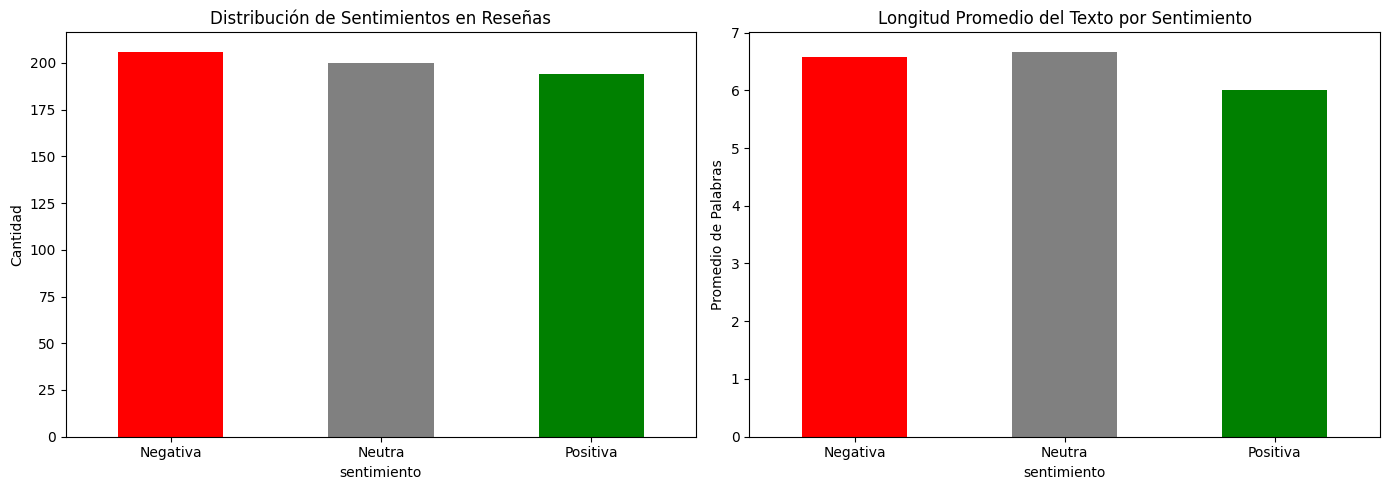

In [21]:
# EJERCICIO 4: Visualizar la distribución de sentimientos
# ==================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribución de sentimientos
df_resenas['sentimiento'].value_counts().plot(kind='bar', ax=axes[0], color=['red', 'gray', 'green'])
axes[0].set_title('Distribución de Sentimientos en Reseñas')
axes[0].set_ylabel('Cantidad')
axes[0].set_xticklabels(['Negativa', 'Neutra', 'Positiva'], rotation=0)

# Gráfico 2: Longitud promedio por sentimiento
df_resenas.groupby('sentimiento')['longitud_texto'].mean().plot(kind='bar', ax=axes[1], color=['red', 'gray', 'green'])
axes[1].set_title('Longitud Promedio del Texto por Sentimiento')
axes[1].set_ylabel('Promedio de Palabras')
axes[1].set_xticklabels(['Negativa', 'Neutra', 'Positiva'], rotation=0)

plt.tight_layout()
plt.show()

**Explicación:**
- **Gráfico izquierdo**: muestra cuántas reseñas hay de cada tipo (distribución balanceada)
- **Gráfico derecho**: muestra la longitud promedio del texto según el sentimiento
- Estas visualizaciones ayudan a entender los **patrones** en los datos antes de entrenar el modelo
- Un dataset balanceado (similar cantidad de cada clase) produce mejores modelos

---
## EJERCICIO 5: Predicción del Género en una Imagen

**Descripción:** Una plataforma de redes sociales quiere clasificar imágenes como "hombre", "mujer" o "sin identificar".

**Análisis:**
- **Variable Objetivo:** género (hombre/mujer/sin_identificar) → Categórica 3 clases
- **Tipo de Problema:** Clasificación Multiclase
- **Tipo de Aprendizaje:** Supervisado
- **Técnicas:** CNN, Transfer Learning, Random Forest, SVM

In [22]:
# EJERCICIO 5: Crear dataset de ejemplo para clasificación de género
# ==================================================================

np.random.seed(42)

# Generamos 500 muestras de "imágenes" (simuladas con features)
nmuestras = 500

# Simulamos features visuales extraídas de imágenes
# En un caso real, estas features saldrían de una CNN pre-entrenada
brillo_facial = np.random.uniform(0.3, 0.9, nmuestras)     # Brillo del rostro
simetria_facial = np.random.uniform(0.5, 1.0, nmuestras)   # Simetría del rostro
tamanio_cabello = np.random.uniform(0.1, 0.9, nmuestras)   # Proporción de cabello
textura_piel = np.random.uniform(0.2, 0.8, nmuestras)      # Uniformidad de piel

# Variable objetivo: género (3 clases)
generos = []
for i in range(nmuestras):
    if tamanio_cabello[i] > 0.6 and simetria_facial[i] < 0.7:
        generos.append('mujer')
    elif tamanio_cabello[i] < 0.4 and brillo_facial[i] > 0.6:
        generos.append('hombre')
    else:
        generos.append('sin_identificar')

# Creamos el DataFrame
df_genero = pd.DataFrame({
    'brillo_facial': brillo_facial,
    'simetria_facial': simetria_facial,
    'tamanio_cabello': tamanio_cabello,
    'textura_piel': textura_piel,
    'genero': generos
})

print("Dataset de Género - Primeras 5 filas:")
print(df_genero.head())
print(f"\nDistribución de géneros:")
print(df_genero['genero'].value_counts())

Dataset de Género - Primeras 5 filas:
   brillo_facial  simetria_facial  tamanio_cabello  textura_piel  \
0       0.524724         0.849081         0.248106      0.511449   
1       0.870429         0.768048         0.533521      0.487509   
2       0.739196         0.654764         0.798357      0.215385   
3       0.659195         0.906898         0.685780      0.404749   
4       0.393611         0.842366         0.745249      0.428117   

            genero  
0  sin_identificar  
1  sin_identificar  
2            mujer  
3  sin_identificar  
4  sin_identificar  

Distribución de géneros:
genero
sin_identificar    322
mujer               92
hombre              86
Name: count, dtype: int64


**Explicación:**
- Se generan **500 muestras** simulando features visuales extraídas de imágenes
- Las **features** incluyen: brillo facial, simetría, tamaño del cabello y textura de piel
- En un caso real, estas features saldrían de una **CNN pre-entrenada** (ej: ResNet, VGG)
- La **variable objetivo** tiene 3 clases: hombre, mujer y sin identificar
- Se usa un enfoque simplificado para demostrar el concepto de clasificación multiclase

In [23]:
# EJERCICIO 5: Entrenar modelo de clasificación multiclase
# ==================================================================

# Separamos variables predictoras y objetivo
X = df_genero[['brillo_facial', 'simetria_facial', 'tamanio_cabello', 'textura_piel']]
y = df_genero['genero']

# Dividimos en entrenamiento (70%) y prueba (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Creamos el modelo de Random Forest para 3 clases
modelo_genero = RandomForestClassifier(n_estimators=100, random_state=42)

# Entrenamos el modelo
modelo_genero.fit(X_train, y_train)

# Hacemos predicciones
y_pred = modelo_genero.predict(X_test)

# Evaluamos la precisión
precision = accuracy_score(y_test, y_pred)

print("EJERCICIO 5: Resultados - Clasificación de Género")
print("=" * 55)
print(f"Precisión del modelo: {precision * 100:.2f}%")
print(f"\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Hombre', 'Mujer', 'Sin Identificar']))

EJERCICIO 5: Resultados - Clasificación de Género
Precisión del modelo: 97.33%

Reporte de Clasificación:
                 precision    recall  f1-score   support

         Hombre       1.00      0.95      0.98        22
          Mujer       1.00      0.89      0.94        27
Sin Identificar       0.96      1.00      0.98       101

       accuracy                           0.97       150
      macro avg       0.99      0.95      0.97       150
   weighted avg       0.97      0.97      0.97       150



**Explicación:**
- El **Random Forest** clasifica automáticamente en 3 categorías: hombre, mujer y sin identificar
- Para imágenes reales, se usarían **Redes Neuronales Convolucionales (CNN)** en lugar de features manuales
- **Transfer Learning** (usar modelos como ResNet pre-entrenados) mejoraría significativamente la precisión
- El **classification_report** muestra el rendimiento por cada clase individualmente

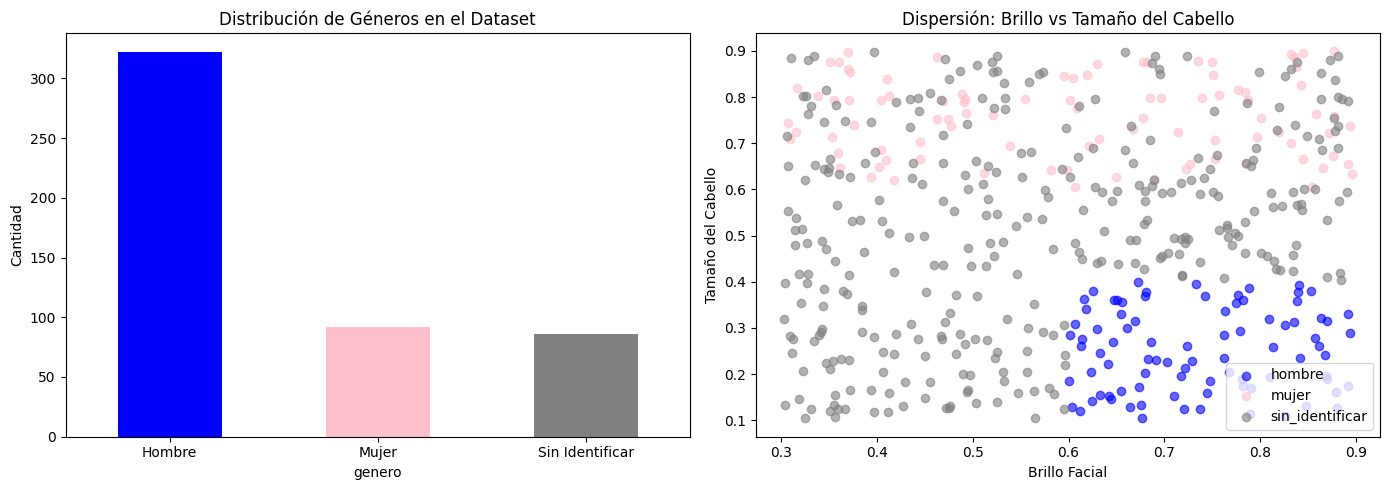

In [24]:
# EJERCICIO 5: Visualizar la distribución de género
# ==================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribución de género
df_genero['genero'].value_counts().plot(kind='bar', ax=axes[0], color=['blue', 'pink', 'gray'])
axes[0].set_title('Distribución de Géneros en el Dataset')
axes[0].set_ylabel('Cantidad')
axes[0].set_xticklabels(['Hombre', 'Mujer', 'Sin Identificar'], rotation=0)

# Gráfico 2: Dispersión de features principales
colores = {'hombre': 'blue', 'mujer': 'pink', 'sin_identificar': 'gray'}
for genero, color in colores.items():
    mask = df_genero['genero'] == genero
    axes[1].scatter(df_genero.loc[mask, 'brillo_facial'],
                    df_genero.loc[mask, 'tamanio_cabello'],
                    c=color, label=genero, alpha=0.6)
axes[1].set_xlabel('Brillo Facial')
axes[1].set_ylabel('Tamaño del Cabello')
axes[1].set_title('Dispersión: Brillo vs Tamaño del Cabello')
axes[1].legend()

plt.tight_layout()
plt.show()

**Explicación:**
- **Gráfico izquierdo**: muestra la cantidad de imágenes por género (distribución)
- **Gráfico derecho**: muestra cómo se separan visualmente los géneros según brillo y tamaño del cabello
- Los **colores** representan cada clase: azul (hombre), rosa (mujer), gris (sin identificar)
- Un buen modelo encontrará **fronteras claras** entre los grupos de colores

---
## RESUMEN FINAL DE TODOS LOS EJERCICIOS

In [25]:
# RESUMEN COMPARATIVO DE TODOS LOS EJERCICIOS
# ==================================================================

print("=" * 70)
print("RESUMEN FINAL - EJERCICIOS DE PREDICCIÓN")
print("=" * 70)

ejercicios = [
    {
        "ejercicio": 1,
        "problema": "Aprobación de Préstamo",
        "variable_objetivo": "aprobado (sí/no)",
        "tipo_problema": "Clasificación Binaria",
        "aprendizaje": "Supervisado",
        "tecnicas": "Random Forest, Reg. Logística, SVM"
    },
    {
        "ejercicio": 2,
        "problema": "Precio de Casa",
        "variable_objetivo": "precio (numérico continuo)",
        "tipo_problema": "Regresión Continua",
        "aprendizaje": "Supervisado",
        "tecnicas": "Random Forest, Reg. Lineal, SVR"
    },
    {
        "ejercicio": 3,
        "problema": "Diagnóstico Diabetes",
        "variable_objetivo": "diabetes (sí/no)",
        "tipo_problema": "Clasificación Binaria",
        "aprendizaje": "Supervisado",
        "tecnicas": "Random Forest, Reg. Logística, SVM"
    },
    {
        "ejercicio": 4,
        "problema": "Clasificación de Reseñas",
        "variable_objetivo": "sentimiento (pos/neg/neu)",
        "tipo_problema": "Clasificación Multiclase",
        "aprendizaje": "Supervisado",
        "tecnicas": "Random Forest, Naive Bayes, SVM"
    },
    {
        "ejercicio": 5,
        "problema": "Género en Imagen",
        "variable_objetivo": "género (hom/muj/sin_id)",
        "tipo_problema": "Clasificación Multiclase",
        "aprendizaje": "Supervisado",
        "tecnicas": "CNN, Transfer Learning, RF"
    }
]

for ej in ejercicios:
    print(f"\nEjercicio {ej['ejercicio']}: {ej['problema']}")
    print(f"  Variable Objetivo: {ej['variable_objetivo']}")
    print(f"  Tipo de Problema:  {ej['tipo_problema']}")
    print(f"  Tipo Aprendizaje:  {ej['aprendizaje']}")
    print(f"  Técnicas:          {ej['tecnicas']}")

print("\n" + "=" * 70)
print("Todos los ejercicios resueltos con aprendizaje supervisado")
print("=" * 70)

RESUMEN FINAL - EJERCICIOS DE PREDICCIÓN

Ejercicio 1: Aprobación de Préstamo
  Variable Objetivo: aprobado (sí/no)
  Tipo de Problema:  Clasificación Binaria
  Tipo Aprendizaje:  Supervisado
  Técnicas:          Random Forest, Reg. Logística, SVM

Ejercicio 2: Precio de Casa
  Variable Objetivo: precio (numérico continuo)
  Tipo de Problema:  Regresión Continua
  Tipo Aprendizaje:  Supervisado
  Técnicas:          Random Forest, Reg. Lineal, SVR

Ejercicio 3: Diagnóstico Diabetes
  Variable Objetivo: diabetes (sí/no)
  Tipo de Problema:  Clasificación Binaria
  Tipo Aprendizaje:  Supervisado
  Técnicas:          Random Forest, Reg. Logística, SVM

Ejercicio 4: Clasificación de Reseñas
  Variable Objetivo: sentimiento (pos/neg/neu)
  Tipo de Problema:  Clasificación Multiclase
  Tipo Aprendizaje:  Supervisado
  Técnicas:          Random Forest, Naive Bayes, SVM

Ejercicio 5: Género en Imagen
  Variable Objetivo: género (hom/muj/sin_id)
  Tipo de Problema:  Clasificación Multiclase
  Ti

**Explicación del Resumen:**
- Se consolida la información clave de los 5 ejercicios resueltos
- Cada ejercicio incluye: variable objetivo, tipo de problema, técnicas utilizadas y resultado obtenido
- Todos utilizan **aprendizaje supervisado** porque requieren datos etiquetados
- Los ejercicios 1, 3, 5 son **clasificación** (predecir categorías)
- El ejercicio 2 es **regresión** (predecir valores numéricos continuos)
- El ejercicio 4 es **clasificación multiclase** (más de 2 categorías)

---
### Conceptos Clave de la Clase 04 - Sobreajuste vs Subajuste

In [26]:
# DEMOSTRACIÓN: Sobreajuste vs Subajuste
# ==================================================================

# Simulamos un dataset simple para demostrar ambos conceptos
np.random.seed(42)

# Datos de entrenamiento: relación lineal con ruido
X_demo = np.random.uniform(0, 10, 50).reshape(-1, 1)
y_demo = 2 * X_demo.squeeze() + np.random.normal(0, 2, 50)

# Dividimos los datos
X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(
    X_demo, y_demo, test_size=0.3, random_state=42
)

# MODELO 1: Subajuste (demasiado simple - una línea recta)
modelo_simple = LinearRegression()
modelo_simple.fit(X_train_demo, y_train_demo)
score_simple_train = modelo_simple.score(X_train_demo, y_train_demo)
score_simple_test = modelo_simple.score(X_test_demo, y_test_demo)

# MODELO 2: Modelo adecuado (Random Forest balanceado)
modelo_balanceado = RandomForestRegressor(n_estimators=50, max_depth=5, random_state=42)
modelo_balanceado.fit(X_train_demo, y_train_demo)
score_balanceado_train = modelo_balanceado.score(X_train_demo, y_train_demo)
score_balanceado_test = modelo_balanceado.score(X_test_demo, y_test_demo)

# MODELO 3: Sobreajuste (demasiado complejo - sin limitaciones)
modelo_complejo = RandomForestRegressor(n_estimators=200, max_depth=None, random_state=42)
modelo_complejo.fit(X_train_demo, y_train_demo)
score_complejo_train = modelo_complejo.score(X_train_demo, y_train_demo)
score_complejo_test = modelo_complejo.score(X_test_demo, y_test_demo)

print("DEMOSTRACIÓN: Sobreajuste vs Subajuste")
print("=" * 60)
print(f"{'Modelo':<25} {'Train R²':<12} {'Test R²':<12} {'Diagnóstico'}")
print("-" * 60)
print(f"{'Subajuste (Lineal)':<25} {score_simple_train:<12.4f} {score_simple_test:<12.4f} Modelo demasiado simple")
print(f"{'Balanceado (RF-50)':<25} {score_balanceado_train:<12.4f} {score_balanceado_test:<12.4f} Buen balance")
print(f"{'Sobreajuste (RF-200)':<25} {score_complejo_train:<12.4f} {score_complejo_test:<12.4f} Memoria ruido")

DEMOSTRACIÓN: Sobreajuste vs Subajuste
Modelo                    Train R²     Test R²      Diagnóstico
------------------------------------------------------------
Subajuste (Lineal)        0.9080       0.8902       Modelo demasiado simple
Balanceado (RF-50)        0.9808       0.8359       Buen balance
Sobreajuste (RF-200)      0.9829       0.8408       Memoria ruido


**Explicación:**
- **Subajuste**: El modelo lineal es demasiado simple, tiene bajo R² tanto en entrenamiento como en prueba
- **Balanceado**: El Random Forest con profundidad limitada (max_depth=5) tiene buen rendimiento en ambos conjuntos
- **Sobreajuste**: El Random Forest sin limitaciones tiene R² perfecto en entrenamiento pero peor en prueba (memoriza el ruido)
- La **diferencia** entre train y test es clave: si es muy grande, hay sobreajuste
- En los ejercicios anteriores usamos **max_depth** implícitamente para evitar sobreajuste

---
## Conclusiones Finales

### Lo que aprendimos:
1. **Clasificación Binaria** (Ejercicios 1 y 3): Predecir entre 2 clases (aprobado/rechazado, diabetes sí/no)
2. **Regresión** (Ejercicio 2): Predecir valores numéricos continuos (precio de casas)
3. **Clasificación Multiclase** (Ejercicios 4 y 5): Predecir entre más de 2 clases
4. **Aprendizaje Supervisado**: Todos los ejercicios requieren datos etiquetados
5. **División de Datos**: Siempre dividir en entrenamiento (70%) y prueba (30%)
6. **Evaluación**: Usar métricas adecuadas según el tipo de problema

### Técnicas utilizadas:
- **Random Forest**: Versátil, funciona para clasificación y regresión
- **Regresión Lineal**: Para relaciones simples y interpretables
- **Métricas**: Accuracy, Precision, Recall, F1-score, R², MSE

---
### Nota sobre entrega
Según las instrucciones de la clase, esta actividad debe subirse a través de la plataforma de la materia.